# Laptop Price Prediction with Classical Machine Learning Algorithms

In [1]:
# Standard Library
import warnings
import os

# Data Manipulation
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Display Configuration
warnings.filterwarnings('ignore')

print("Environment ready. All libraries loaded successfully.")

Environment ready. All libraries loaded successfully.


## Load the Data

In [2]:
DATA_PATH = "../data/raw/laptop_price.csv"
df = pd.read_csv(DATA_PATH)
print("Data loaded successfully")

Data loaded successfully


# Exploratory Data Analysis 

In [3]:
# How big is the data?
df.shape

(1303, 12)

In [4]:
# How does the data look like?
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [5]:
# What are the data type of the columns?
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1303 non-null   int64  
 1   Company           1303 non-null   object 
 2   TypeName          1303 non-null   object 
 3   Inches            1303 non-null   float64
 4   ScreenResolution  1303 non-null   object 
 5   Cpu               1303 non-null   object 
 6   Ram               1303 non-null   object 
 7   Memory            1303 non-null   object 
 8   Gpu               1303 non-null   object 
 9   OpSys             1303 non-null   object 
 10  Weight            1303 non-null   object 
 11  Price             1303 non-null   float64
dtypes: float64(2), int64(1), object(9)
memory usage: 122.3+ KB


In [6]:
# Are there any missing values?
df.isnull().sum()

Unnamed: 0          0
Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

In [7]:
# Are there any duplicate values?
df.duplicated().sum()

0

## Data Cleaning, Preprocessing, and Visualization

In [8]:
# Removing Unnecessary columns, including Unnamed: 0
df.drop(columns=['Unnamed: 0'], inplace=True)
df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [9]:
# Change the type of Ram and weight as number
df['Ram'] = df['Ram'].str.replace('GB', '').astype('int64')
df['Weight'] = df['Weight'].str.replace('kg', '').astype('float64')

df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080


In [10]:
# Check the data type of the column again
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1303 non-null   object 
 1   TypeName          1303 non-null   object 
 2   Inches            1303 non-null   float64
 3   ScreenResolution  1303 non-null   object 
 4   Cpu               1303 non-null   object 
 5   Ram               1303 non-null   int64  
 6   Memory            1303 non-null   object 
 7   Gpu               1303 non-null   object 
 8   OpSys             1303 non-null   object 
 9   Weight            1303 non-null   float64
 10  Price             1303 non-null   float64
dtypes: float64(3), int64(1), object(7)
memory usage: 112.1+ KB


In [11]:
# Statistical Analysis
df.describe()

,Inches,Ram,Weight,Price
count,1303.000000,1303.000000,1303.000000,1303.000000
mean,15.017191,8.382195,2.038734,59870.042910
std,1.426304,5.084665,0.665475,37243.201786
min,10.100000,2.000000,0.690000,9270.720000
25%,14.000000,4.000000,1.500000,31914.720000
50%,15.600000,8.000000,2.040000,52054.560000
75%,15.600000,8.000000,2.300000,79274.246400
max,18.400000,64.000000,4.700000,324954.720000


In [12]:
# Correlation
df.corr(numeric_only=True)

,Inches,Ram,Weight,Price
Inches,1.000000,0.237993,0.827631,0.068197
Ram,0.237993,1.000000,0.383874,0.743007
Weight,0.827631,0.383874,1.000000,0.210370
Price,0.068197,0.743007,0.210370,1.000000


<Axes: >

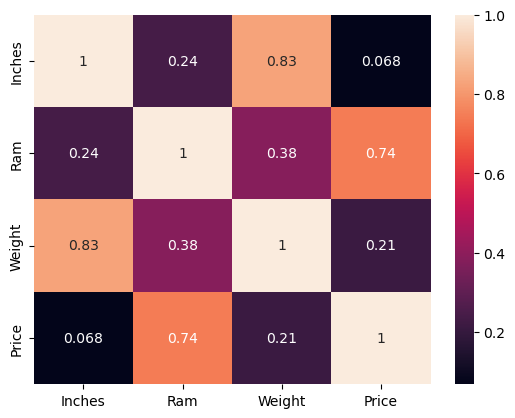

In [13]:
# Correlation Heatmap
sns.heatmap(data=df.corr(numeric_only=True), annot=True)

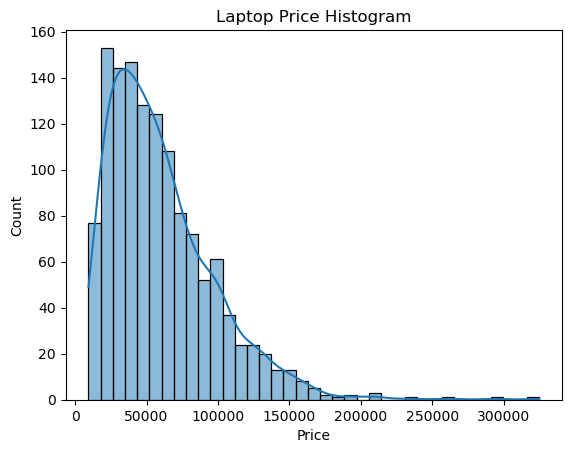

In [14]:
# How the target variable look like?
sns.histplot(df['Price'], kde=True)
plt.title('Laptop Price Histogram')
plt.savefig("../outputs/figures/1_laptop_price_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

> **Key Finding:** The target column **Price** of the data is something similar to **Right skewed Distribution**.

In [15]:
# Which company appears most/less in the data?
df['Company'].value_counts()

Company
Dell         297
Lenovo       297
HP           274
Asus         158
Acer         103
MSI           54
Toshiba       48
Apple         21
Samsung        9
Razer          7
Mediacom       7
Microsoft      6
Xiaomi         4
Vero           4
Chuwi          3
Google         3
Fujitsu        3
LG             3
Huawei         2
Name: count, dtype: int64

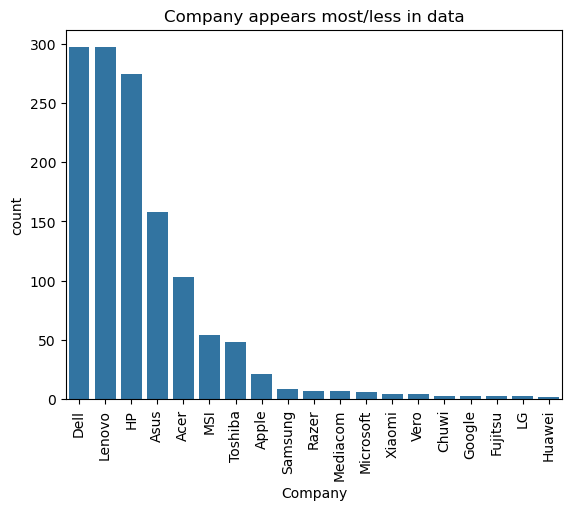

In [16]:
sns.countplot(data=df, x='Company', order=df['Company'].value_counts().index)
plt.title("Company appears most/less in data")
plt.xticks(rotation=90)
plt.savefig("../outputs/figures/2_laptop_companies.png", dpi=150, bbox_inches="tight")
plt.show()

> **Key Finding:** **Dell and Lenevo** laptops are appears most in the data, while **Google, Fujitsu, LG, and Huawei** are less in the data.

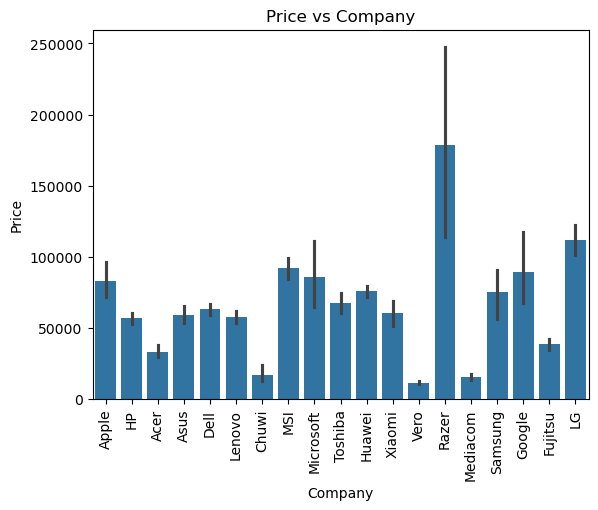

In [17]:
# Which company claims most/less price in the data?
sns.barplot(data=df, x='Company', y='Price')
plt.title("Price vs Company")
plt.xticks(rotation=90)
plt.savefig("../outputs/figures/3_price_vs_company.png", dpi=150, bbox_inches="tight")
plt.show()

> **Key Finding:** The **Razer** company's laptops are too expensive than others. Companies like **LG, Apple, MSI, Microsoft** have affordable laptop prices in the range of nearly 100000.

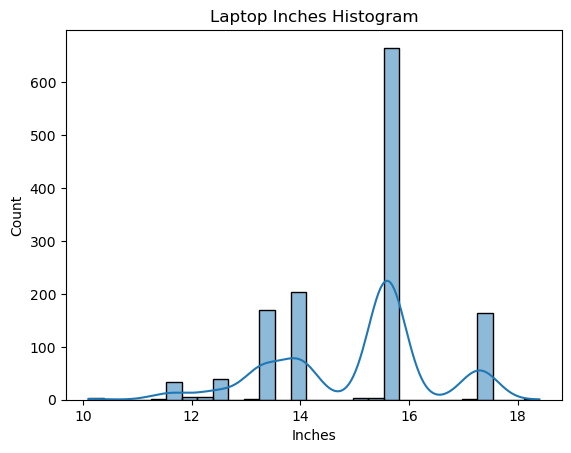

In [18]:
# Inches feature distribution
sns.histplot(data=df, x='Inches', kde=True)
plt.title("Laptop Inches Histogram")
plt.savefig("../outputs/figures/4_laptop_screen_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

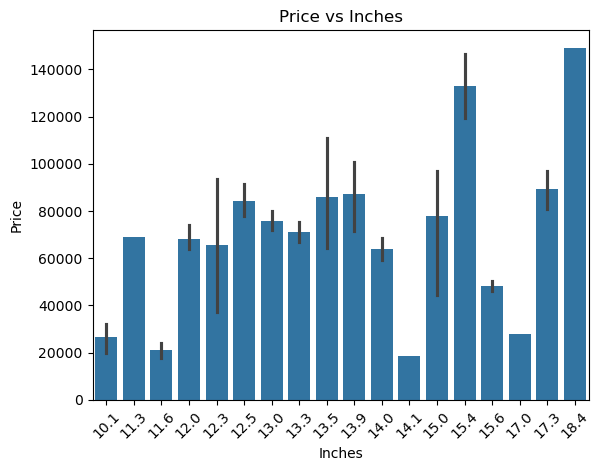

In [19]:
# How the Inches affect laptop prices?
sns.barplot(data=df, x='Inches', y='Price')
plt.title("Price vs Inches")
plt.xticks(rotation=45)
plt.savefig("../outputs/figures/5_price_vs_inches.png", dpi=150, bbox_inches="tight")
plt.show()

> **Key Finding:** Higher screen size affects the Price a bit.

In [20]:
# Which type of laptop appears most/less in the data?
df['TypeName'].value_counts()

TypeName
Notebook              727
Gaming                205
Ultrabook             196
2 in 1 Convertible    121
Workstation            29
Netbook                25
Name: count, dtype: int64

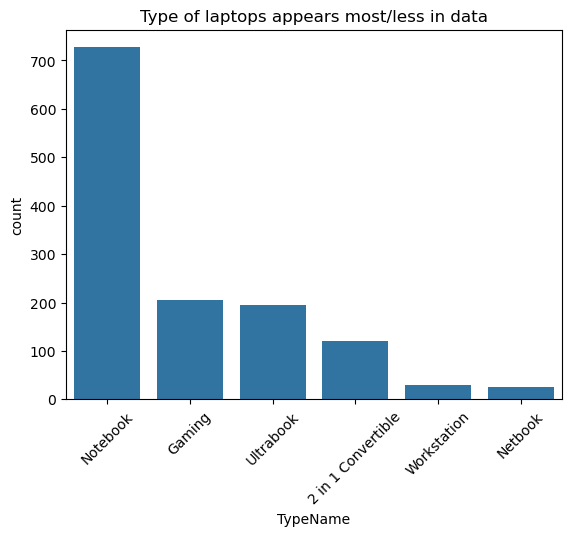

In [21]:
sns.countplot(data=df, x='TypeName', order=df['TypeName'].value_counts().index)
plt.title("Type of laptops appears most/less in data")
plt.xticks(rotation=45)
plt.savefig("../outputs/figures/6_laptop_types.png", dpi=150, bbox_inches="tight")
plt.show()

> **Key Finding:** The laptops which type **Notebook**  are appears most in the data, while **Workstation, Netbook** are appears less in the data.

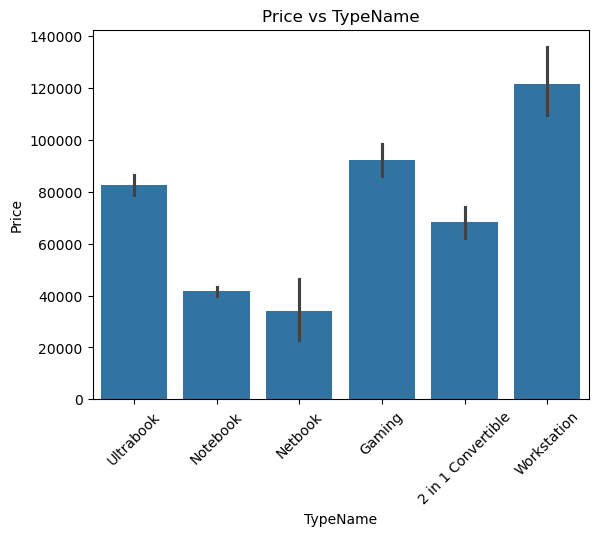

In [22]:
# Which type of laptops claims most/less price
sns.barplot(data=df, x='TypeName', y='Price')
plt.title("Price vs TypeName")
plt.xticks(rotation=45)
plt.savefig("../outputs/figures/7_price_vs_type.png", dpi=150, bbox_inches="tight")
plt.show()

> **Key Finding:** The type **Workstation** of among laptops claims higher price, while **Ultrabook, 2 in 1 Convertible and Gaming** type laptops claims moderate price. The **Notebook and Netbook** are in affordable price range nearly 40000.

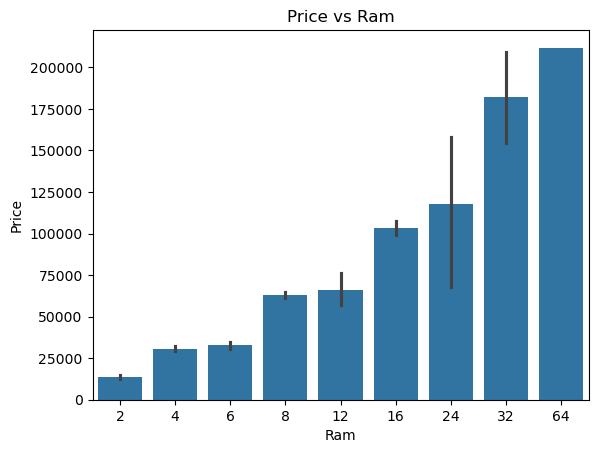

In [23]:
# How Ram affects the laptop's price?
sns.barplot(data=df, x='Ram', y='Price')
plt.title("Price vs Ram")
plt.savefig("../outputs/figures/8_price_vs_ram.png", dpi=150, bbox_inches="tight")
plt.show()

> **Key Finding:** As the **size of Ram** increases, the laptop price is also increasing.

In [24]:
df.columns

Index(['Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram',
       'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'],
      dtype='object')

In [25]:
# How many types of memory appears in data?
df['Memory'].value_counts()

Memory
256GB SSD                        412
1TB HDD                          223
500GB HDD                        132
512GB SSD                        118
128GB SSD +  1TB HDD              94
128GB SSD                         76
256GB SSD +  1TB HDD              73
32GB Flash Storage                38
2TB HDD                           16
64GB Flash Storage                15
512GB SSD +  1TB HDD              14
1TB SSD                           14
256GB SSD +  2TB HDD              10
1.0TB Hybrid                       9
256GB Flash Storage                8
16GB Flash Storage                 7
32GB SSD                           6
180GB SSD                          5
128GB Flash Storage                4
512GB SSD +  2TB HDD               3
16GB SSD                           3
512GB Flash Storage                2
1TB SSD +  1TB HDD                 2
256GB SSD +  500GB HDD             2
128GB SSD +  2TB HDD               2
256GB SSD +  256GB SSD             2
512GB SSD +  256GB SSD         

### Extract essential features from Memory column

In [26]:
df['Memory'] = df['Memory'].str.replace('GB', '')
df['Memory'] = df['Memory'].str.replace('TB', '000')

# Splitting Memory types (if SSD and HDD both appears)
memory = df['Memory'].str.split("+", expand=True)
memory.sample(15)

,0,1
642,512 SSD,None
674,128 SSD,None
374,256 SSD,None
406,512 SSD,None
521,256 SSD,None
1005,256 SSD,None
902,256 SSD,None
1199,256 SSD,1000 HDD
883,1000 HDD,None
138,1000 HDD,None


In [27]:
# Extract different memory (e.g., HDD, SSD)
df['first_memory'] = memory[0].str.strip()
df['second_memory'] = memory[1]

# Apply function to determine what type of memory appears in data
df['first_memory_HDD'] = df['first_memory'].apply(lambda x: 1 if 'HDD' in x else 0)
df['first_memory_SSD'] = df['first_memory'].apply(lambda x: 1 if 'SSD' in x else 0)
df['first_memory_Hybrid'] = df['first_memory'].apply(lambda x: 1 if 'Hybrid' in x else 0)
df['first_memory_Flash_Storage'] = df['first_memory'].apply(lambda x: 1 if 'Flash_Storage' in x else 0)

df['first_memory'] = df['first_memory'].str.replace(r'\D', '', regex=True)
df['second_memory'].fillna("0", inplace=True)

df['second_memory_HDD'] = df['second_memory'].apply(lambda x: 1 if 'HDD' in x else 0)
df['second_memory_SSD'] = df['second_memory'].apply(lambda x: 1 if 'SSD' in x else 0)
df['second_memory_Hybrid'] = df['second_memory'].apply(lambda x: 1 if 'Hybrid' in x else 0)
df['second_memory_Flash_Storage'] = df['second_memory'].apply(lambda x: 1 if 'Flash_Storage' in x else 0)

df['second_memory'] = df['second_memory'].str.replace(r'\D', '', regex=True)

# Change the type
df['first_memory'] = df['first_memory'].astype('int64')
df['second_memory'] = df['second_memory'].astype('int64')

# Calculate HDD, SSD, Hybrid, Flash_Storage
df['HDD'] = (df['first_memory'] * df['first_memory_HDD'] + df['second_memory'] * df['second_memory_HDD'])
df['SSD'] = (df['first_memory'] * df['first_memory_SSD'] + df['second_memory'] * df['second_memory_SSD'])
df['Hybrid'] = (df['first_memory'] * df['first_memory_Hybrid'] + df['second_memory'] * df['second_memory_Hybrid'])
df['Flash_Storage'] = (df['first_memory'] * df['first_memory_Flash_Storage'] + df['second_memory'] * df['second_memory_Flash_Storage'])

# Drop unnecessary columns
df.drop(columns=['first_memory', 'second_memory', 'first_memory_HDD', 'first_memory_SSD', 'first_memory_Hybrid',
                'first_memory_Flash_Storage', 'second_memory_HDD', 'second_memory_SSD', 'second_memory_Hybrid', 
                'second_memory_Flash_Storage', 'Memory'], inplace=True)

df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Gpu,OpSys,Weight,Price,HDD,SSD,Hybrid,Flash_Storage
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832,0,128,0,0
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,Intel HD Graphics 6000,macOS,1.34,47895.5232,0,0,0,0
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,Intel HD Graphics 620,No OS,1.86,30636.0000,0,256,0,0
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,AMD Radeon Pro 455,macOS,1.83,135195.3360,0,512,0,0
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080,0,256,0,0
